# 03 · Fixed effects of price and promotion

This is the second step of step-up model selection (Raudenbush & Bryk, 2002). After the null model of notebook 02, level-1 predictors (the week) are added to the fixed part, while the random intercepts for store, product and the store × product pair (M4) are kept. Only the training sample was used to fit the models: the initial 104 weeks (D11, revised). The final 52 weeks form a retrospective temporal evaluation window with prior exploratory exposure, and none of the fits in this notebook used them.

This notebook **fits no models**: the fits were made by scripts (`scripts/fit_fixed_effects.py` and those of the sensitivity analyses) and stored in `outputs/runs`. The notebook only reads those runs, so the Portuguese and English versions show identical results. The coefficients presented are conditional associations in weeks with recorded transactions, not causal effects.

*Data: dunnhumby Source Files – Breakfast at the Frat.*

In [1]:
LANG = "en"

In [2]:
import warnings

import pandas as pd
from IPython.display import display

from retail_multilevel import interpret, viz
from retail_multilevel.i18n import t
from retail_multilevel.paths import PROCESSED_DIR
from retail_multilevel.runs import load_run
from retail_multilevel.split import model_sample

warnings.filterwarnings("ignore", category=FutureWarning)
viz.use_retina()
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:,.4f}".format)
run = load_run("fixed_effects", "20261124-114202-1fda5a5d")
print(t("data_credit", LANG))
print("run:", run.run_id, "| finished_at:", run.metadata["finished_at"])
sample = run.load_json("sample")
display(pd.Series(sample).to_frame("training sample"))

Data: dunnhumby Source Files – Breakfast at the Frat
run: 20261124-114202-1fda5a5d | finished_at: 2026-11-24T11:45:14.599134


,training sample
nobs,347092
n_fallback_rows_in_train,111
excluded_fallback,False
n_pairs,3859
log_disc_mean,-0.0688
log_disc_sd,0.1468
share_disc_below_5pct,0.2501


The run that was read is identified above (identifier and finish time). The training sample has 347,092 rows and 3,859 store × product pairs. The log of the discount (`LOG_DISC`, below) has a mean of −0.069 and a standard deviation of 0.147, and 25.0% of the weeks have `LOG_DISC` below −0.05, that is, a discount of about 5% or more off the regular price. There is, therefore, plenty of discount variation from which to extract the association. Of the training rows, 111 use the fallback base price (`BASE_PRICE = PRICE`), which section 8 addresses.

## 1. The specification

The response is log(units), so each coefficient is a log-change, converted to a percentage change further on. The fixed part was built from decisions D12 to D14, which are development decisions motivated by the initial exploration of the panel (D11, revised). Price does not enter as a single term, because the log price varies mostly between products, and that difference is entangled with the characteristics of the product. The log price is therefore decomposed into three parts. The first is the depth of the temporary discount, `LOG_DISC = log(price / base price)`, whose coefficient is the elasticity to the discount (Tellis, 1988; Bijmolt et al., 2005). The second is the deviation of the regular price from the mean of its own pair, `LOG_BASE_DEV`, whose coefficient is the elasticity to the regular price within the pair over time. The third is the pair mean itself, `LOG_BASE_MEAN` (a Mundlak term), which absorbs the association between the price level and the pair and keeps this difference between pairs from contaminating the within-pair coefficients (Mundlak, 1978). The pair means were computed on the training rows only, and a missing base price was filled using only the history of the pair (D8, revised), so that nothing posterior to the time of the observation enters the specification.

Only the regular price was decomposed into within-pair and between-pair terms. The discount and the promotion variables enter as they are, and the within-pair reading of those regressors is examined by a sensitivity analysis with pair and week fixed effects (section 9). The three promotion variables (`FEATURE`, `DISPLAY` and `TPR_ONLY`) are 0/1 indicators. Because the discount already enters through its depth, these indicators measure the association **beyond** the price cut, with the discount held constant. This separation partly resolves the near-collinearity between discount and promotion seen in the data cleaning, because the price only falls below base in weeks with a promotion, but the overlap between promotion types and discount bands remains limited (section 4). Seasonality is represented by three pairs of Fourier terms (Hyndman & Athanasopoulos, 2021) of the week of the year (`SIN_k` and `COS_k`, with k from 1 to 3), global, and the trend by a linear variable in years (`TREND`). In this way, 52 weekly dummy variables, heavy and noisy for two years of training, are avoided.

The likelihood-ratio (LR) tests that compare different fixed parts use **maximum likelihood (ML)** fits, because the restricted likelihood (REML) depends on the fixed part and is therefore not comparable across these models (Pinheiro & Bates, 2000). The coefficients and variances of the final model, in turn, come from a new REML fit (Bates et al., 2015), which estimates the variances with less bias. The four models, F0 to F3, are shown next.

In [3]:
fits = run.load_table("fits")
display(fits[["name", "formula"]])

,name,formula
0,F0_null,LOG_UNITS ~ 1 + (1 | STORE_NUM) + (1 | UPC) + (1 | STORE_NUM:UPC)
1,F1_price,LOG_UNITS ~ 1 + LOG_DISC + LOG_BASE_DEV + LOG_BASE_MEAN + (1 | STORE_NUM) + (1 | UPC) + (1 | STORE_NUM:UPC)
2,F2_promo,LOG_UNITS ~ 1 + LOG_DISC + LOG_BASE_DEV + LOG_BASE_MEAN + FEATURE + DISPLAY + TPR_ONLY + (1 | STORE_NUM) + (1 | UPC) + (1 | STORE_NUM:UPC)
3,F3_season,LOG_UNITS ~ 1 + LOG_DISC + LOG_BASE_DEV + LOG_BASE_MEAN + FEATURE + DISPLAY + TPR_ONLY + TREND + SIN_1 + COS_1 + SIN_2 + COS_2 + SIN_3 + COS_3 + (1 | STORE_NUM) + (1 | UPC) + (1 | STORE_NUM:UPC)


## 2. The fixed-effects step-up

Each step adds a block of terms to the fixed part: price (F1), promotions (F2) and seasonality with trend (F3). The table gives the number of parameters, the ML log-likelihood, the AIC, the BIC and the number of convergence messages.

In [4]:
display(fits[["name", "nobs", "npar", "loglik", "aic", "bic", "n_messages"]])

,name,nobs,npar,loglik,aic,bic,n_messages
0,F0_null,347092,5,"-346,785.4346","693,580.8691","693,634.6559",0
1,F1_price,347092,8,"-295,885.3621","591,786.7242","591,872.7830",0
2,F2_promo,347092,11,"-275,144.9318","550,311.8637","550,430.1945",0
3,F3_season,347092,18,"-274,532.4014","549,100.8028","549,294.4350",0


The ML log-likelihood rises from −346,785 (F0) to −295,885 (F1), −275,145 (F2) and −274,532 (F3), and the AIC falls from 693,581 to 591,787, 550,312 and 549,101, with 5, 8, 11 and 18 parameters. The BIC also decreases at every step (from 693,635 to 549,294), so the penalty for additional parameters does not reverse any of the gains. No fit produced convergence messages.

In [5]:
lr = run.load_table("lr")


def format_p(p):
    return "< 1e-300" if p < 1e-300 else f"{p:.2e}"


display(lr.assign(p_value=lr["p_value"].map(format_p), p_naive=lr["p_naive"].map(format_p)))

,restricted,full,stat,df,p_value,p_naive
0,F0_null,F1_price,"101,800.1449",3,< 1e-300,< 1e-300
1,F1_price,F2_promo,"41,480.8605",3,< 1e-300,< 1e-300
2,F2_promo,F3_season,"1,225.0609",7,2.69e-260,2.69e-260


Here, unlike in notebook 02, the tests do not involve variances on the boundary of the parameter space: they concern fixed effects, and the reference is an ordinary χ², which is why `p_value` and `p_naive` coincide. The statistics are 101,800 (F0 against F1, 3 degrees of freedom), 41,481 (F1 against F2, 3 degrees) and 1,225 (F2 against F3, 7 degrees). The first two p-values are below 1e-300 and the third is 2.69e-260.

With 347,092 rows, however, any term would have a negligible p-value, so significance alone says little. The relevant criterion is magnitude: the price block makes the largest contribution (101,800), followed by the promotion block (41,481), while seasonality, at 1,225, is about 83 times smaller than price.

## 3. The coefficients and what they mean

The chart shows the coefficients of the final model (F3, by REML) with 95% Wald intervals, on the log scale, without the intercept and the Fourier terms. The intervals are so narrow that they are barely distinguishable from the point, but they are conditional on the F3 specification and understate the uncertainty, as sections 9 and 10 show.

,term,estimate,std_error,z,ci_low,ci_high
0,(Intercept),2.9610,0.1749,16.9260,2.6181,3.3039
1,LOG_DISC,-1.6852,0.0107,-157.4917,-1.7062,-1.6642
2,LOG_BASE_DEV,-1.5921,0.0119,-133.9563,-1.6154,-1.5688
3,LOG_BASE_MEAN,-0.8797,0.1054,-8.3477,-1.0862,-0.6731
4,FEATURE,0.4972,0.0043,116.2815,0.4889,0.5056
5,DISPLAY,0.4087,0.0036,113.3137,0.4016,0.4157
6,TPR_ONLY,-0.0412,0.0037,-11.0859,-0.0485,-0.0339
7,TREND,-0.0214,0.0018,-12.2339,-0.0249,-0.0180


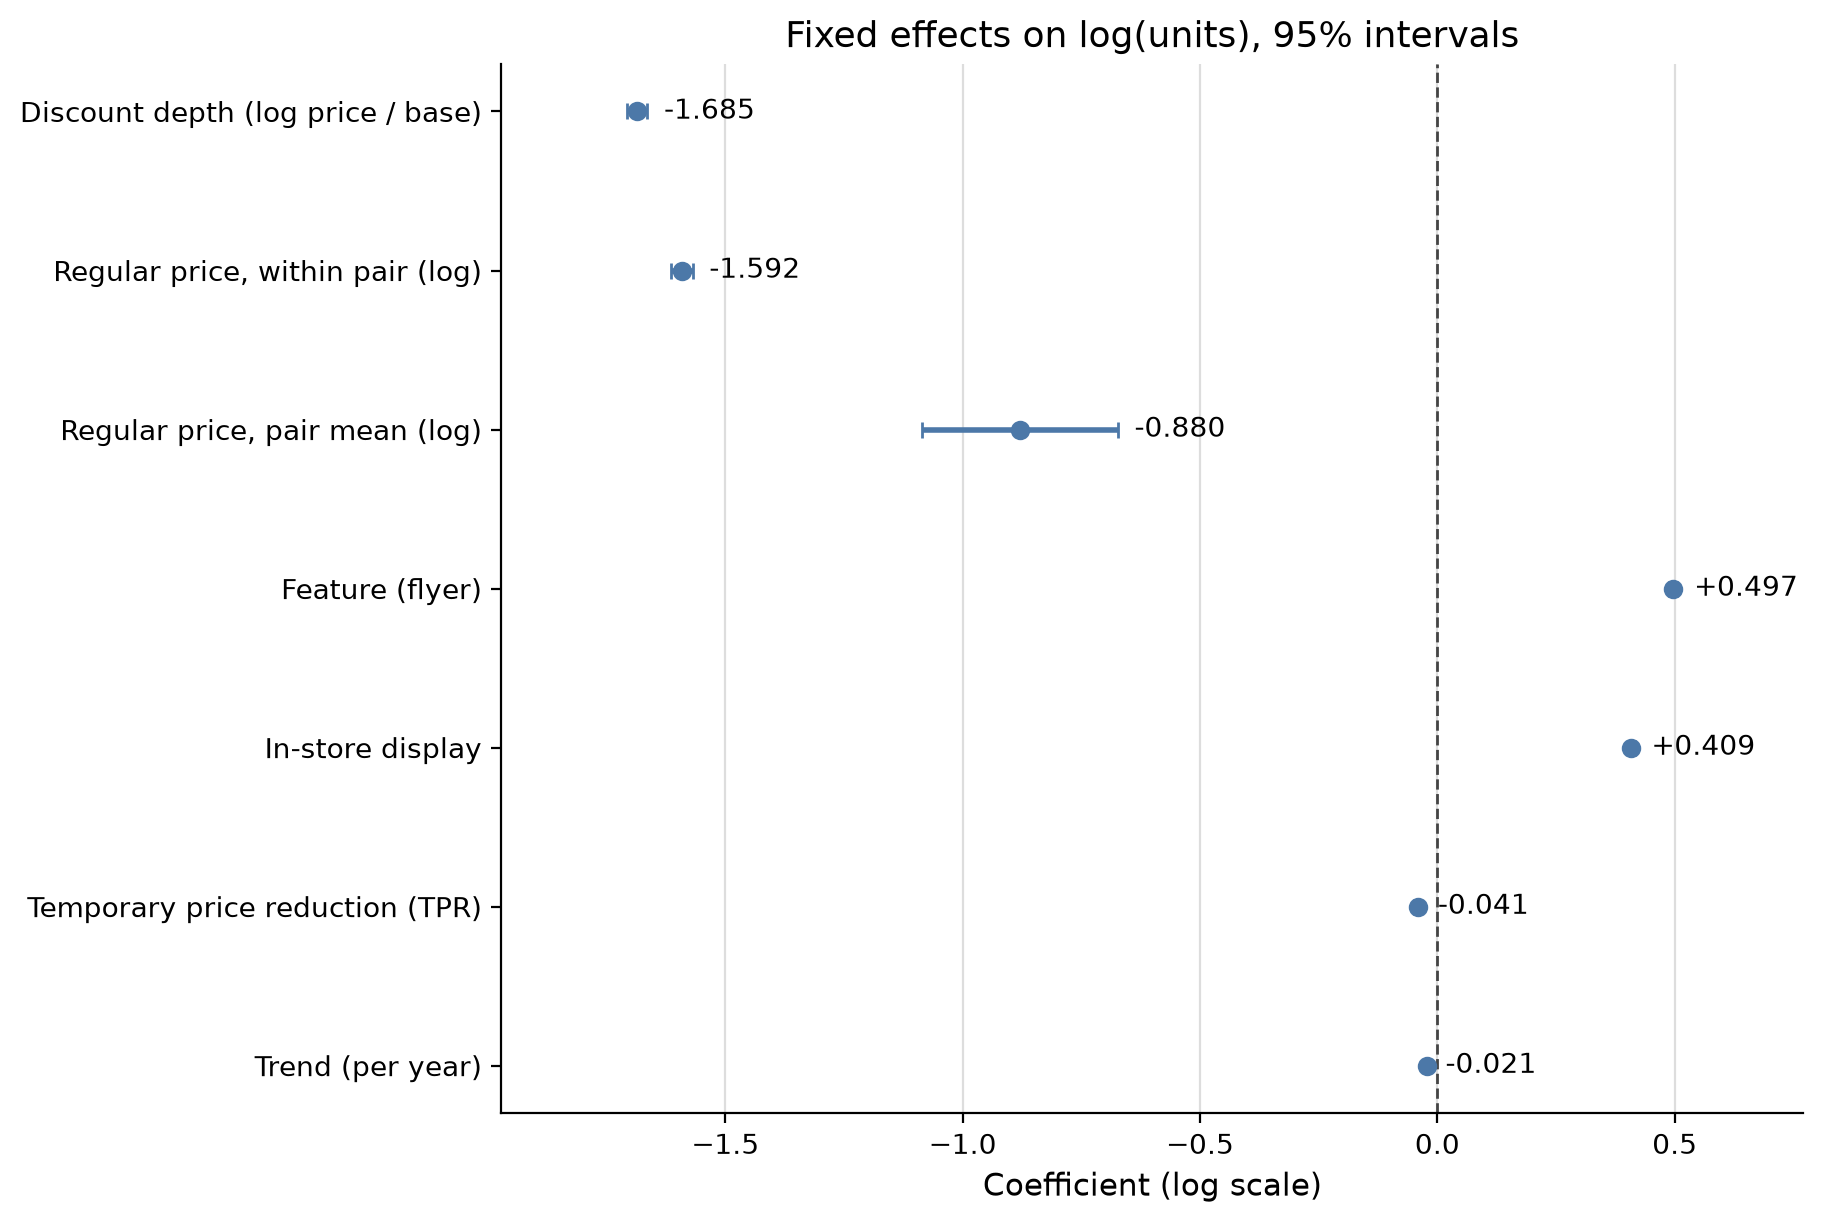

In [6]:
fixef = run.load_table("fixef")
fig = viz.plot_coefficients(fixef, LANG)
display(fixef[~fixef["term"].str.startswith(("SIN_", "COS_"))])

Because the response is in logs, a log-discount coefficient is an elasticity, and the following table converts each coefficient (and its confidence limits, through the same transformation) into a percentage change in units: a 10% price cut through the discount, a 10% rise in the regular price, and the presence of each promotion or of one more year. Each row holds the other covariates constant.

In [7]:
with pd.option_context("display.float_format", "{:,.1f}".format):
    display(interpret.effects_table(fixef, LANG))

,Effect,Change in units (%),"95% CI, lower (%)","95% CI, upper (%)"
0,10% deeper discount,19.4,19.2,19.7
1,10% higher regular price,-14.1,-14.3,-13.9
2,"Feature (flyer), beyond the price cut",64.4,63.0,65.8
3,"In-store display, beyond the price cut",50.5,49.4,51.5
4,"TPR only, beyond the price cut",-4.0,-4.7,-3.3
5,One more year (trend),-2.1,-2.5,-1.8


The discount coefficient is −1.685 (95% Wald CI: −1.706 to −1.664), so a 10% deeper discount is associated with about 19.4% more units (95% CI: 19.2% to 19.7%). The regular price, measured within the pair, has a coefficient of −1.592, and a 10% higher regular price is associated with about 14.1% fewer units. Feature has a coefficient of 0.497, that is, about 64.4% more units, and display 0.409, or about 50.5% more, both with the discount and the other covariates held constant. The trend is −0.021 per year, about 2.1% fewer units each year.

**TPR.** The coefficient of `TPR_ONLY` is −0.041, that is, −4.0% in units (95% CI: −4.7% to −3.3%). This value is the transformation of the flag coefficient with the depth of the discount and the other covariates held constant, that is, the comparison between two weeks with the same discount, one flagged as TPR and one with no promotion. That comparison practically does not exist in the training data: all 47,610 `TPR_ONLY` rows have a discount (none below 5%, as the cross-tabulation of section 4 shows), and none of the 247,331 rows without a promotion has a price below base. Comparing TPR with a week without promotion in the same discount band is therefore an extrapolation, which depends on the additive functional form of the model. The coefficient alone does not allow stating that TPR reduces sales or that its value comes only from the discount. The business reading requires scenarios that combine the depth of the discount and the promotion type, presented in section 4.

The feature and display coefficients contrast with the raw lifts (Blattberg & Neslin, 1989) of notebook 01 (feature +195%, display +129% and TPR +33%). In that notebook, the comparisons were descriptive and mixed the promotion with the price cut that accompanies it. Here, the depth of the discount, the regular price level, the trend and seasonality are controlled, and what remains for feature (+64%) and display (+50%) is a fraction of the raw lift: a part of what looked like a promotion effect accompanies the price cut.

The coefficient of `LOG_BASE_MEAN` (−0.880, 95% CI: −1.086 to −0.673) deserves a different reading. It compares pairs with different average regular prices and is therefore an association **between pairs**, compositional in nature (pairs with a higher average regular price tend to sell fewer units per week), and not the effect of changing the price of an item.

## 4. Joint discount-and-promotion scenarios

Because the discount and the promotion type vary together in the data, the business reading rests on scenarios that combine the two, not on isolated contrasts of one coefficient. The cross-tabulation below shows the overlap in the training rows: the number of rows of each promotion type in each discount band (`1 − PRICE / BASE_PRICE`).

In [8]:
panel = pd.read_parquet(PROCESSED_DIR / "panel.parquet")
train = model_sample(panel, "train")
display(interpret.promo_by_discount_band(train, LANG))

,No price cut,0-5%,5-10%,10-20%,20-30%,Above 30%
No promotion,247331,0,0,0,0,0
TPR only,0,0,155,26592,11992,8871
Feature only,793,846,835,3871,4128,3922
Display only,8489,2148,1198,5085,3138,3129
Feature and display,265,454,728,3025,4431,5666


None of the 247,331 rows without a promotion has a discount, and none of the 47,610 TPR rows has a discount of up to 5%: 155 fall between 5% and 10%, and most of them, 26,592, between 10% and 20%. Feature and display, by contrast, occur in every band, including with no price cut (793 feature-only rows and 8,489 display-only rows).

Each scenario below is measured relative to a regular week, with no discount and no promotion, by `exp(β_discount · log(1 − d) + β_promotion) − 1`, with the other covariates held constant. The last two columns count the training rows that realise exactly the promotion combination of the scenario with a discount within 3 percentage points of the scenario value, which indicates whether the scenario lies within the observed ranges. The values are point estimates: the coefficient table does not store the covariances, and the individual intervals cannot be combined.

In [9]:
scenarios = interpret.DEFAULT_SCENARIOS
scenario_tab = interpret.scenario_table(
    interpret.scenario_effects(fixef, scenarios), interpret.scenario_support(train, scenarios, tol=0.03), LANG
)
with pd.option_context("display.float_format", "{:,.1f}".format):
    display(scenario_tab)

,Scenario,Discount (%),Change in units vs. regular week (%),Training rows realising it,Share of training rows (%)
0,"Regular week (no discount, no promotion)",0.0,0.0,247331,71.3
1,TPR with 10% discount,10.0,14.6,9393,2.7
2,TPR with 20% discount,20.0,39.8,10185,2.9
3,"Feature, no discount",0.0,64.4,1055,0.3
4,Feature with 20% discount,20.0,139.5,2574,0.7
5,"Display, no discount",0.0,50.5,8622,2.5
6,Display with 20% discount,20.0,119.2,2272,0.7
7,Feature and display with 25% discount,25.0,301.8,2767,0.8


A TPR with a 10% discount is associated with 14.6% more units than the regular week (9,393 training rows, 2.7%), and with a 20% discount with 39.8% more (10,185 rows, 2.9%); both scenarios lie within the observed ranges. Feature with a 20% discount (+139.5%, 2,574 rows), display with 20% (+119.2%, 2,272 rows) and feature with display at a 25% discount (+301.8%, 2,767 rows) also have support, although small, of 0.7% to 0.8% of the rows each. Without a discount, display (+50.5%, 8,622 rows, 2.5%) and feature (+64.4%, 1,055 rows, 0.3%) have the lowest support among the scenarios, especially feature.

The values depend on the functional form. The elasticity is constant in log(1 − d), the flags and the discount are additive on the log scale, and feature and display have no estimated interaction: the 301.8% for feature with display is the product of the separately estimated effects (e^0.497 × e^0.409 × 0.75^−1.685 − 1), although there are rows of that combination in every discount band. The contrast between TPR and display at the same 20% discount (+39.8% against +119.2%) uses rows observed in both scenarios, but remains a conditional association, subject to the selection of when and where each promotion is applied. No profitability ranking follows from these numbers: the margin and the cost of promotions are not in the data, and a pricing recommendation or an incremental ROI would require causal identification and margin data. The decision layer of the project is therefore a scenario analysis.

## 5. Seasonality and trend

The six Fourier terms have no direct reading individually. The seasonal profile they imply is computed next, as a percentage effect on units relative to the average week of the year.

,week_of_year,effect_pct
28,29,-4.2231
1,2,6.6175


,term,estimate,std_error,z,ci_low,ci_high
8,SIN_1,-0.0017,0.0014,-1.2547,-0.0044,0.0010
9,COS_1,0.0337,0.0013,26.6984,0.0313,0.0362
10,SIN_2,-0.0037,0.0013,-2.9136,-0.0062,-0.0012
11,COS_2,0.0148,0.0013,11.7528,0.0123,0.0173
12,SIN_3,0.0183,0.0013,14.4553,0.0158,0.0208
13,COS_3,0.0107,0.0013,8.4942,0.0082,0.0132


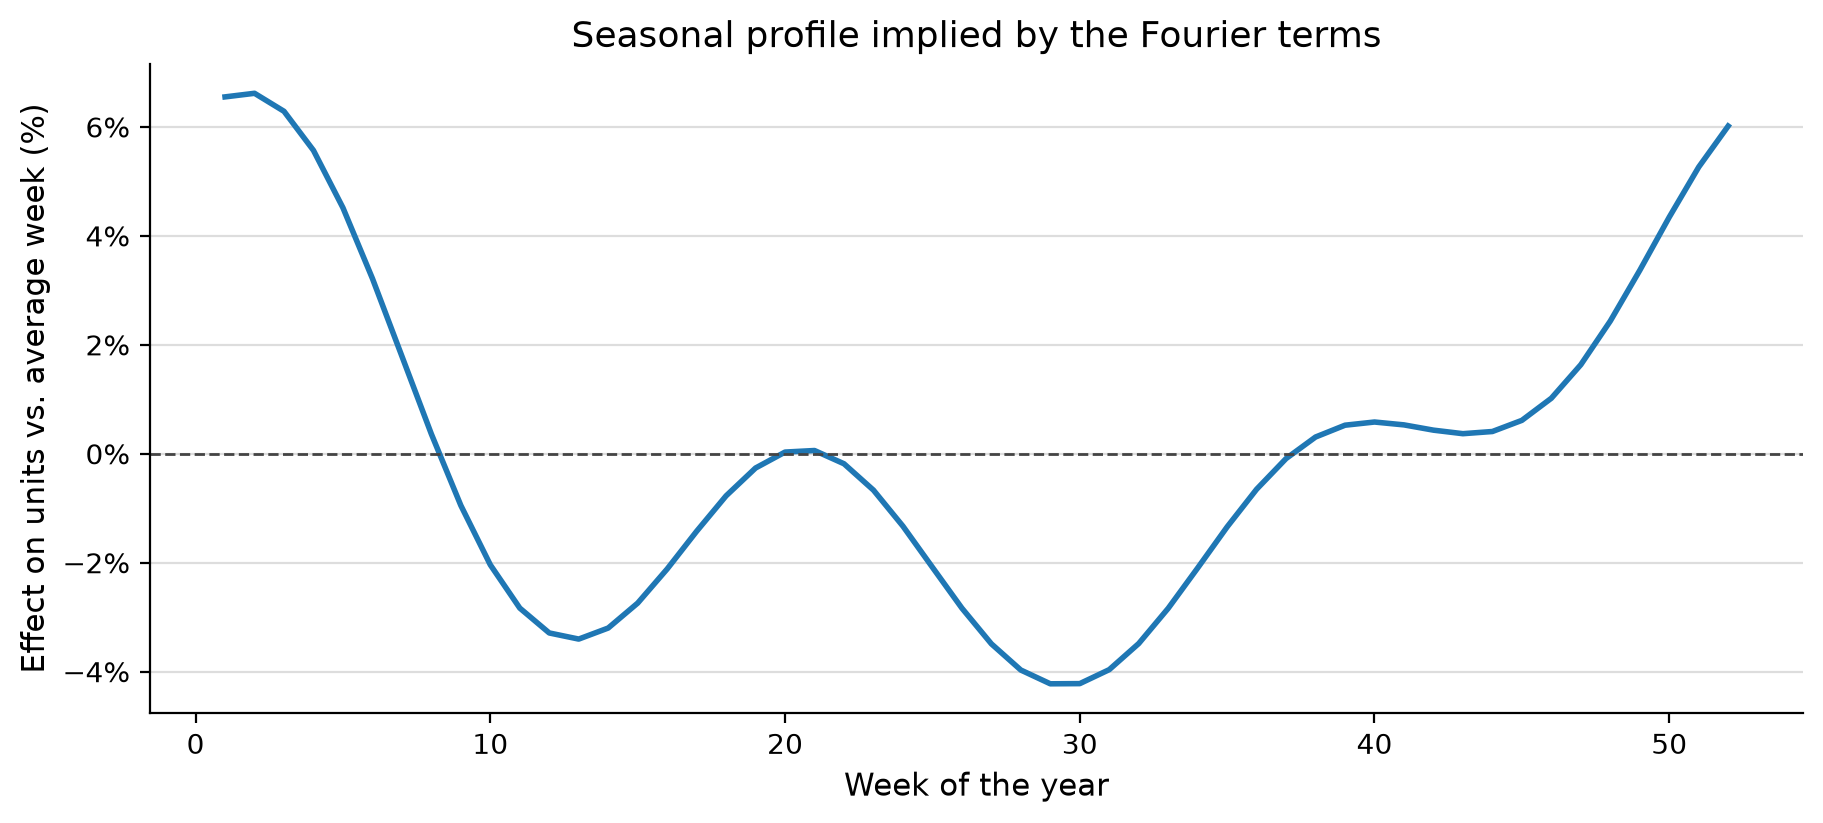

In [10]:
profile = interpret.seasonal_profile(fixef)
fig = viz.plot_seasonality(profile, LANG)
display(profile.loc[[profile["effect_pct"].idxmin(), profile["effect_pct"].idxmax()]])
display(fixef[fixef["term"].str.startswith(("SIN_", "COS_"))])

The amplitude of seasonality is small compared with the price and promotion associations: the weakest week of the year (week 29) has about 4.2% fewer units than the average week, and the strongest (week 2) about 6.6% more. The difference between the extremes is about 11 percentage points, to be compared with the 19.4% associated with a 10% deeper discount. Some individual terms have small coefficients (for example, `SIN_1`, −0.002, whose interval includes zero), but the block as a whole is clearly different from zero by the likelihood-ratio test (1,225). The trend, finally, is a decline of about 2.1% per year (95% CI: −2.5% to −1.8%) over the two training seasons, after controlling for price, promotion and seasonality.

## 6. How much variance price and promotion explain: pseudo-R² per level

In multilevel models, the proportional reduction of each variance component, from the null model to the final model, indicates the level at which the predictors act (Raudenbush & Bryk, 2002). The calculation uses the REML fits of F0 and F3, and the reduction is 1 − final variance / null-model variance.

,group,var_null,var_final,reduction
0,Store × product,0.1431,0.1490,-0.0418
1,Store,0.1623,0.1665,-0.0260
2,Product,0.9646,0.6815,0.2934
3,Residual,0.4151,0.2724,0.3437


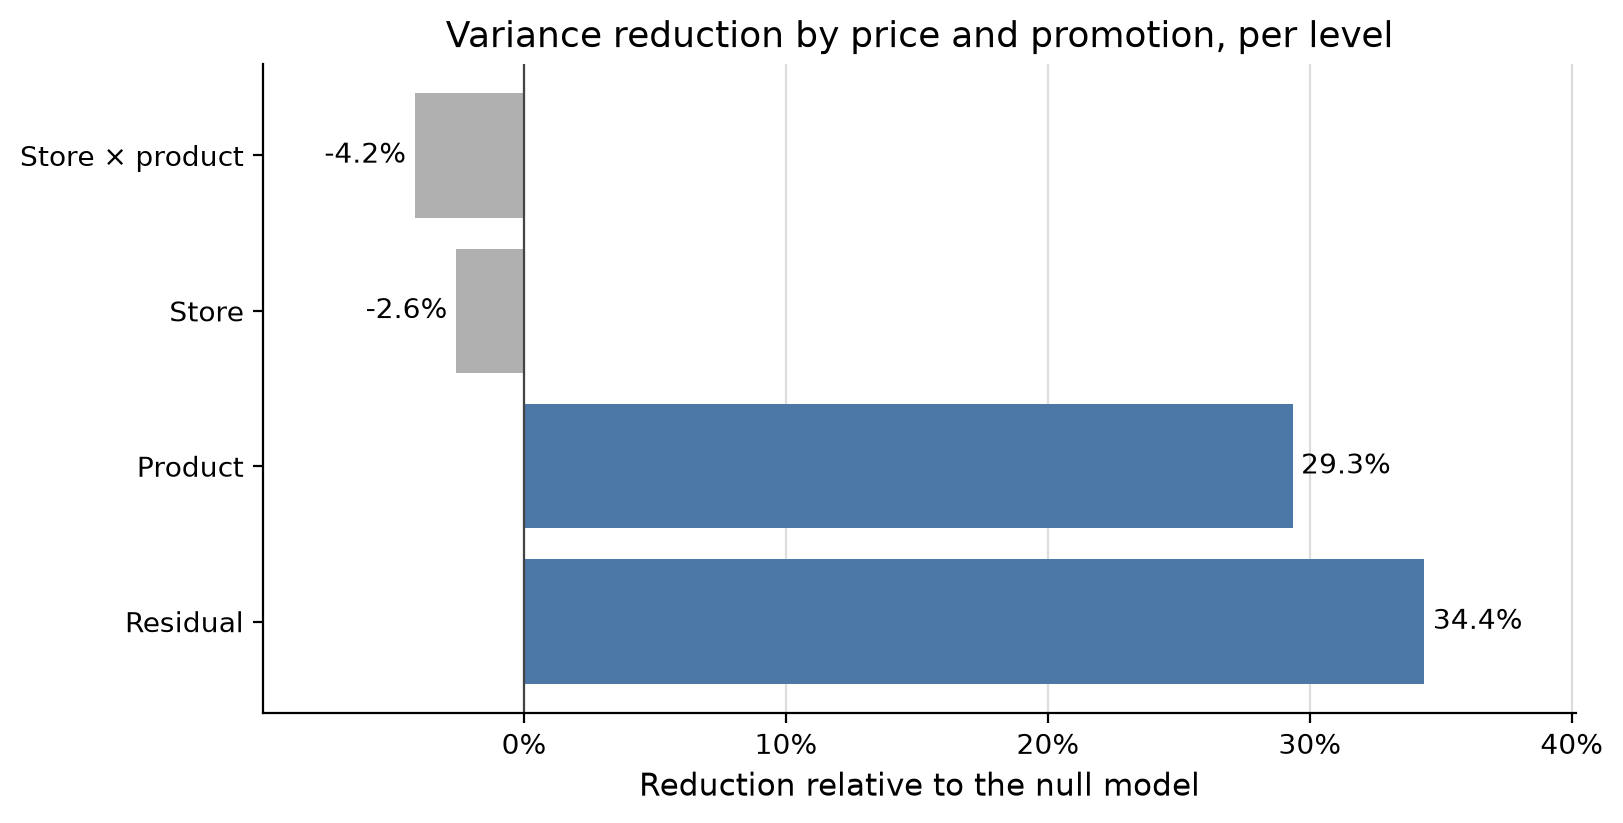

In [11]:
pseudo = run.load_table("pseudo_r2")
fig = viz.plot_pseudo_r2(pseudo, LANG)
display(pseudo.assign(group=pseudo["group"].map(lambda g: viz.group_label(g, LANG))))

The residual, which represents the week-to-week movement within the pair, falls by 34.4% (from 0.415 to 0.272), so price and promotion explain about a third of the weekly variance within the pair. The product variance falls by 29.3% (from 0.965 to 0.682): because the regular price level distinguishes products, this is consistent with the average price of the pair explaining part of the difference between products. The store (−2.6%) and pair (−4.2%) variances, in contrast, increase slightly.

These small negative values are a known artefact of pseudo-R² in multilevel models: when a predictor absorbs variance at one level, the variance can be reallocated between levels, and the component of another level can grow a little without indicating a worse model. They should not be read as a loss of information, only as an indication that price and promotion act mostly on the residual and on the product, and very little on the store and on the pair.

## 7. Single-level versus multilevel

The same fixed part as F3 was fitted in two single-level ways (Gelman & Hill, 2007): a pooled OLS, which ignores the hierarchy, and an OLS with product fixed effects (UPC dummy variables). The chart compares the estimates of the four most relevant coefficients (point ± 1.96 standard errors) across the three methods, and the table gives the values.

method,ols_pooled,ols_upc_fe,multilevel
term,,,
LOG_DISC,-0.3588,-1.4052,-1.6852
LOG_BASE_DEV,-0.9921,-1.4592,-1.5921
FEATURE,0.9080,0.4541,0.4972
DISPLAY,0.6507,0.5511,0.4087


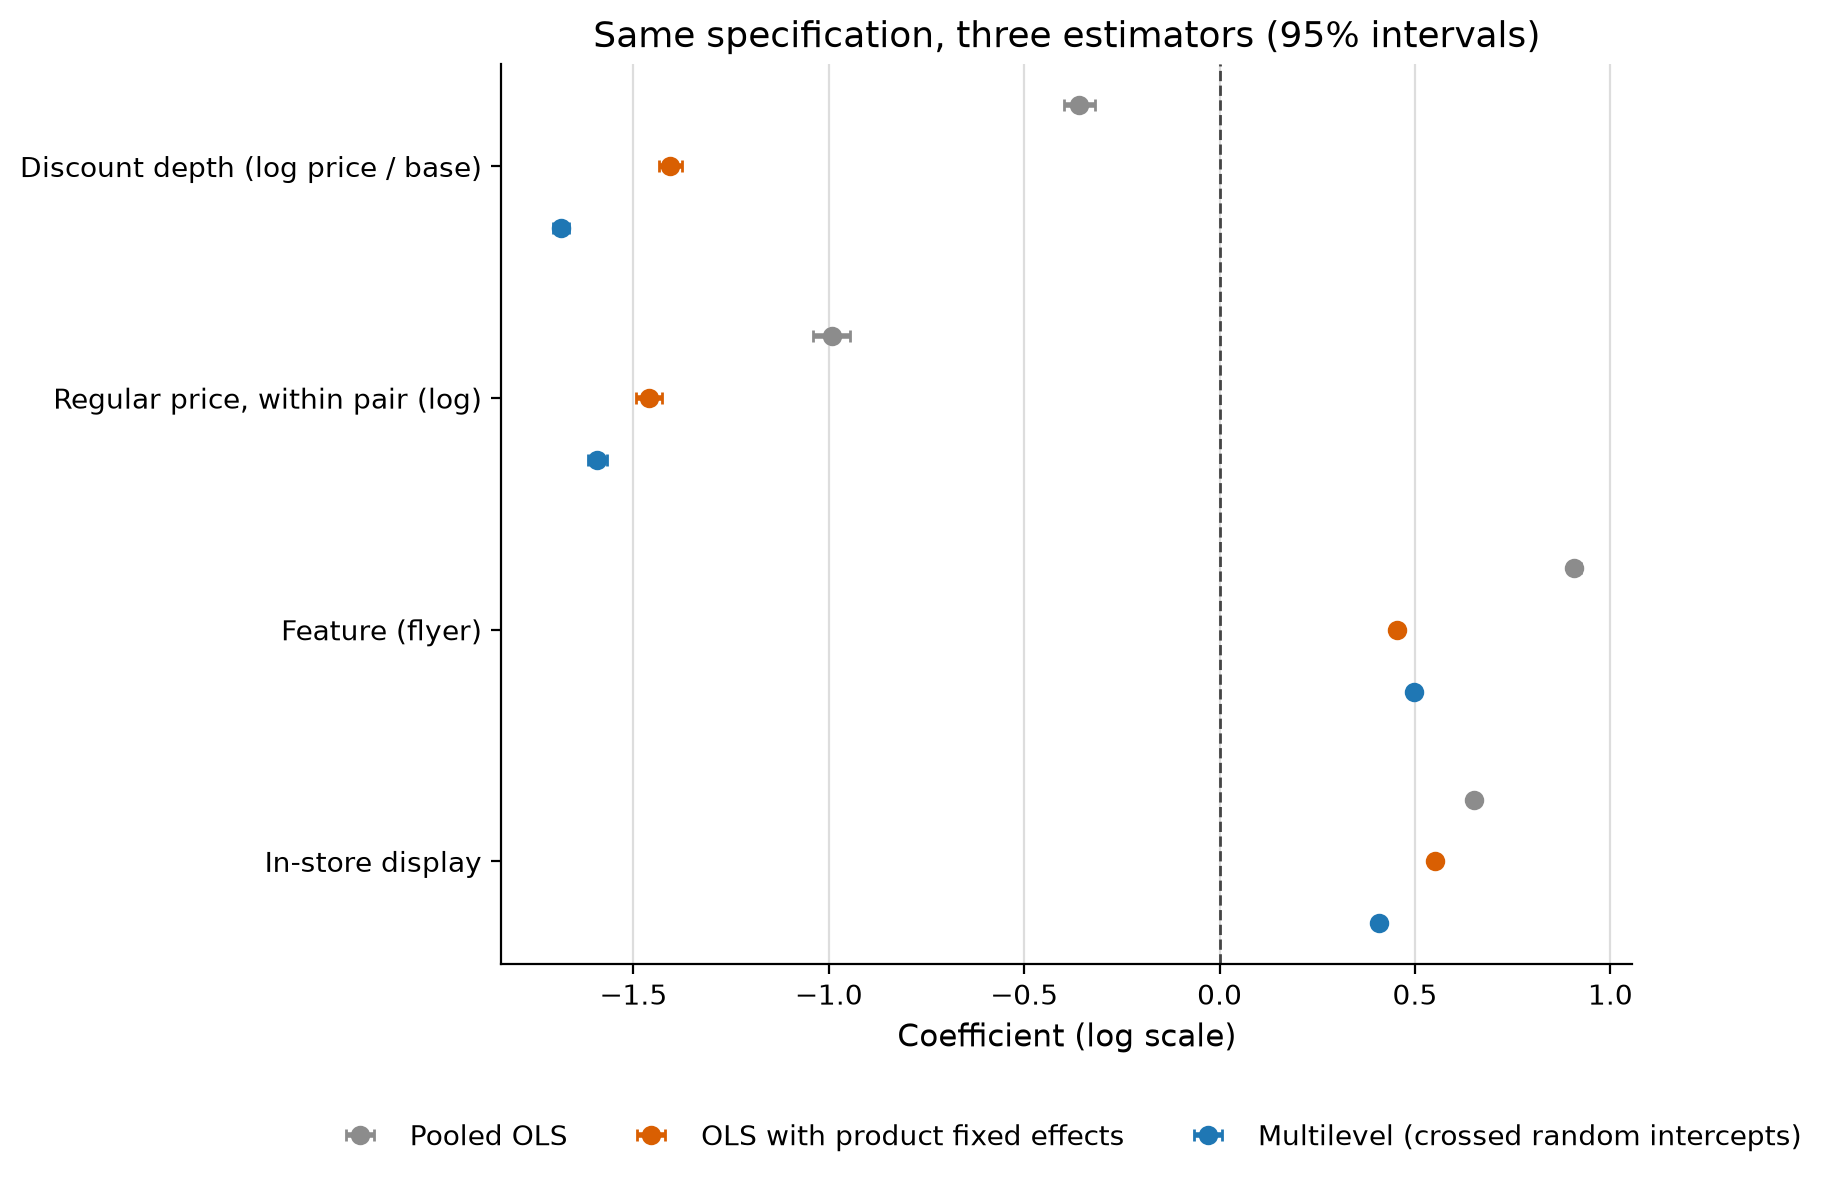

In [12]:
comparison = interpret.method_comparison_table(run.load_table("ols_pooled"), fixef)
fig = viz.plot_method_comparison(comparison, LANG)
estimates = comparison.pivot(index="term", columns="method", values="estimate")
display(estimates.loc[viz.COMPARISON_TERMS, ["ols_pooled", "ols_upc_fe", "multilevel"]])

The elasticity to the discount is −0.359 in the pooled OLS, −1.405 in the OLS with product fixed effects and −1.685 in the multilevel model. The pooled OLS attenuates the elasticity by about a factor of 4.7 and, at the same time, inflates the effects of feature (0.908 against 0.497 in the multilevel model) and display (0.651 against 0.409). The OLS with product fixed effects comes closer to the multilevel model on the discount (−1.405) and feature (0.454), but still diverges on display (0.551) and on the within-pair regular price (−1.459 against −1.592). None of the intervals of the two OLS models contains the multilevel estimate of the discount, and these intervals, moreover, assume independent rows, a hypothesis that notebook 02 itself showed to be inadequate (a correlation of 75.4% between weeks of the same pair).

These results are consistent with the idea that the pooled OLS mixes variation between pairs and variation within the pair: if discounts and promotions are concentrated in pairs whose sales levels already differ, this composition is entangled with the association of the discount. This is an explanation compatible with the numbers, not a demonstration. What the numbers show, concretely, is that ignoring the hierarchy changes the answer: the estimated elasticity to the discount, the basis of any price analysis, changes from −0.36 to −1.69 depending on the method.

## 8. Sensitivity: without the fallback base-price rows

The revised D8 rule fills a missing base price only with the previous week of the same pair. When there is no history, `BASE_PRICE = PRICE` holds, and the discount of the row is set to zero. The following table counts the fallback rows of the panel and of the training sample and distributes them by promotion type.

In [13]:
fallback = train[train["BASE_FALLBACK"]]
counts = {"fallback_rows_panel": int(panel["BASE_FALLBACK"].sum()), "fallback_rows_train": len(fallback)}
display(pd.Series(counts).to_frame("n"))
display(interpret.promo_by_discount_band(fallback, LANG))

,n
fallback_rows_panel,141
fallback_rows_train,111


,No price cut,0-5%,5-10%,10-20%,20-30%,Above 30%
No promotion,0,0,0,0,0,0
TPR only,0,0,0,0,0,0
Feature only,18,0,0,0,0,0
Display only,69,0,0,0,0,0
Feature and display,24,0,0,0,0,0


The panel has 141 fallback rows, of which 111 are in the training sample. All of them are in promotion weeks: 18 with feature only, 69 with display only and 24 with both, none with TPR, and all record a zero discount, although a discount may have occurred. The base price appears to be missing precisely in promotion weeks, and that is the cost of the rule. The sensitivity analysis refits F3 by REML without those 111 rows (run `fixed_effects_no_fallback`), and the following table places it next to F3.

In [14]:
run_nf = load_run("fixed_effects_no_fallback", "20261124-114601-c4b16e68")
print("run:", run_nf.run_id, "| nobs:", run_nf.load_json("sample")["nobs"])
nofb = interpret.compare_estimates(fixef, run_nf.load_table("fixef"))
main_terms = ~nofb["term"].str.startswith(("SIN_", "COS_"))
display(nofb[main_terms].rename(columns={"estimate_other": "estimate_no_fallback", "se_other": "se_no_fallback"}))

run: 20261124-114601-c4b16e68 | nobs: 346981


,term,estimate,std_error,estimate_no_fallback,se_no_fallback,difference,se_ratio
0,(Intercept),2.9610,0.1749,2.9508,0.1750,-0.0102,1.0002
1,LOG_DISC,-1.6852,0.0107,-1.6848,0.0107,0.0003,1.0002
2,LOG_BASE_DEV,-1.5921,0.0119,-1.5910,0.0119,0.0011,1.0006
3,LOG_BASE_MEAN,-0.8797,0.1054,-0.8710,0.1054,0.0086,1.0000
4,FEATURE,0.4972,0.0043,0.4972,0.0043,-0.0001,1.0008
5,DISPLAY,0.4087,0.0036,0.4090,0.0036,0.0003,1.0009
6,TPR_ONLY,-0.0412,0.0037,-0.0413,0.0037,-0.0000,1.0001
7,TREND,-0.0214,0.0018,-0.0215,0.0018,-0.0000,1.0001


Without the fallback rows (346,981 rows), the estimates change very little: the discount goes from −1.6852 to −1.6848, the within-pair regular price from −1.5921 to −1.5910 (a difference of 0.0011, the largest among the price and promotion terms), feature stays at 0.4972, display goes from 0.4087 to 0.4090 and TPR from −0.0412 to −0.0413. The largest difference is that of the pair-mean term, from −0.8797 to −0.8710 (0.0086). The effect of the rule is therefore negligible for the conclusions, and the standard errors do not change appreciably. This does not remove the limitation: in those 111 rows, the realised discount is recorded as zero in feature or display weeks.

## 9. Sensitivity: within-pair reading with pair and week fixed effects

Because only the regular price was decomposed into within-pair and between-pair terms, the discount and the promotion variables still mix within-pair and between-pair variation. To examine the within-pair reading, an OLS with pair and week fixed effects was fitted, estimated by the *within* transformation (Wooldridge, 2010), with pair-clustered standard errors (CR1; Cameron & Miller, 2015), on the same 347,092 training rows and 3,859 pairs (run `fe_sensitivity`). The week effects absorb common shocks, seasonality and trend. The table places the estimates and standard errors next to those of F3.

In [15]:
run_fe = load_run("fe_sensitivity", "20261124-135553-5c4b797b")
print("run:", run_fe.run_id, "| nobs:", run_fe.load_json("sample")["nobs"])
within = interpret.compare_estimates(
    fixef, run_fe.load_table("fe_two_way"), se_col="se_cluster", term_map={"LOG_BASE_PRICE": "LOG_BASE_DEV"}
)
display(within.rename(columns={"estimate_other": "estimate_fe", "se_other": "se_cluster_fe"}))

run: 20261124-135553-5c4b797b | nobs: 347092


,term,estimate,std_error,estimate_fe,se_cluster_fe,difference,se_ratio
0,LOG_DISC,-1.6852,0.0107,-1.7031,0.0437,-0.0180,4.0839
1,LOG_BASE_DEV,-1.5921,0.0119,-1.5980,0.0297,-0.0059,2.4994
2,FEATURE,0.4972,0.0043,0.4924,0.0104,-0.0048,2.4295
3,DISPLAY,0.4087,0.0036,0.4047,0.0080,-0.0040,2.2192
4,TPR_ONLY,-0.0412,0.0037,-0.0427,0.0090,-0.0015,2.4278


The point estimates coincide with those of F3 within 0.02: the discount is −1.703 against −1.685 (the largest difference, −0.018), the regular price −1.598 against −1.592, feature 0.492 against 0.497, display 0.405 against 0.409 and TPR −0.043 against −0.041. The within-pair reading, with time control, therefore confirms the F3 magnitudes also for the discount and the flags, which were not decomposed. The discount estimate (−1.703) is close to the multilevel one, and not to the pooled OLS one (−0.359).

The pair-clustered standard errors are 2.2 to 4.1 times larger than the Wald ones of F3 (the ratio is 4.1 for the discount and 2.2 for display). The Wald intervals of F3 are thus conditional on the F3 specification and too narrow for the uncertainty the data carry, which the next section details.

## 10. Residual dependence: lags and common week shocks

The Wald intervals of F3 assume independent residuals once the random effects are accounted for. The assumption was checked by refitting F3 by REML on the training sample (run `residual_diagnostics`) and examining the conditional residuals, that is, those from which the fixed effects and the predicted random effects were subtracted. The first chart shows the correlation, within the same pair, between the residual of week t and that of week t + k, with the pairs pooled.

run: 20261124-115221-9c67822a | nobs: 347092


,lag,corr,n_pairs_of_obs
0,1,0.1958,327045
1,2,0.1173,323155
2,3,0.0922,319363
3,4,0.0960,315637


,corr,n
0,0.1920,343233


,CATEGORY,corr,n_pairs_of_obs
0,BAG SNACKS,0.2531,80998
1,COLD CEREAL,0.2185,113046
2,FROZEN PIZZA,0.1789,67712
3,ORAL HYGIENE PRODUCTS,0.1426,65289


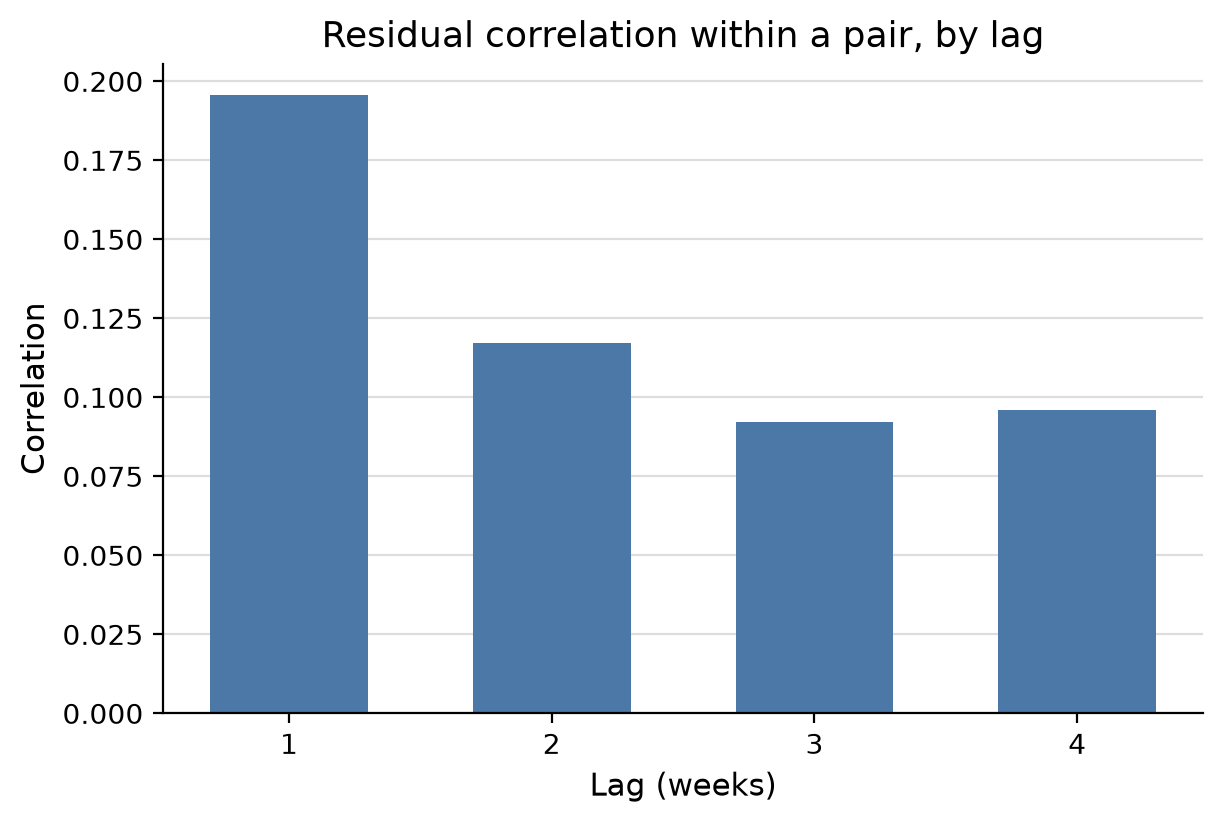

In [16]:
run_diag = load_run("residual_diagnostics", "20261124-115221-9c67822a")
print("run:", run_diag.run_id, "| nobs:", run_diag.load_json("key_numbers")["nobs"])
lag_corr = run_diag.load_table("lag_corr")
fig = viz.plot_residual_lag_corr(lag_corr, LANG)
display(lag_corr)
display(run_diag.load_table("consecutive"))
display(run_diag.load_table("lag1_by_category"))

The correlation between consecutive weeks of the same pair is 0.196 (327,045 comparisons), and the lags of 2, 3 and 4 weeks have 0.117, 0.092 and 0.096. The dependence decays but does not vanish within four weeks. Between consecutive observed rows of the pair, whatever the calendar gap, the correlation is 0.192 (343,233 comparisons). The lag-1 correlation varies by category, from 0.143 in oral hygiene to 0.253 in bag snacks, with boxed cereal and frozen pizza at intermediate values.

,value
sigma2,0.269424
n_weeks,104.000000
var_week_means,0.007861
var_expected_independent,0.000081
variance_ratio,97.192216
share_week,0.028161
share_week_expected,0.000297
autocorr_week_means,-0.004669
share_category_week,0.063634
share_category_week_expected,0.001196


,value
weeks_outside_band,79
weeks,104
largest_shock_week,61
largest_shock_week_end,2010-03-17
largest_shock_mean_resid,-0.5824


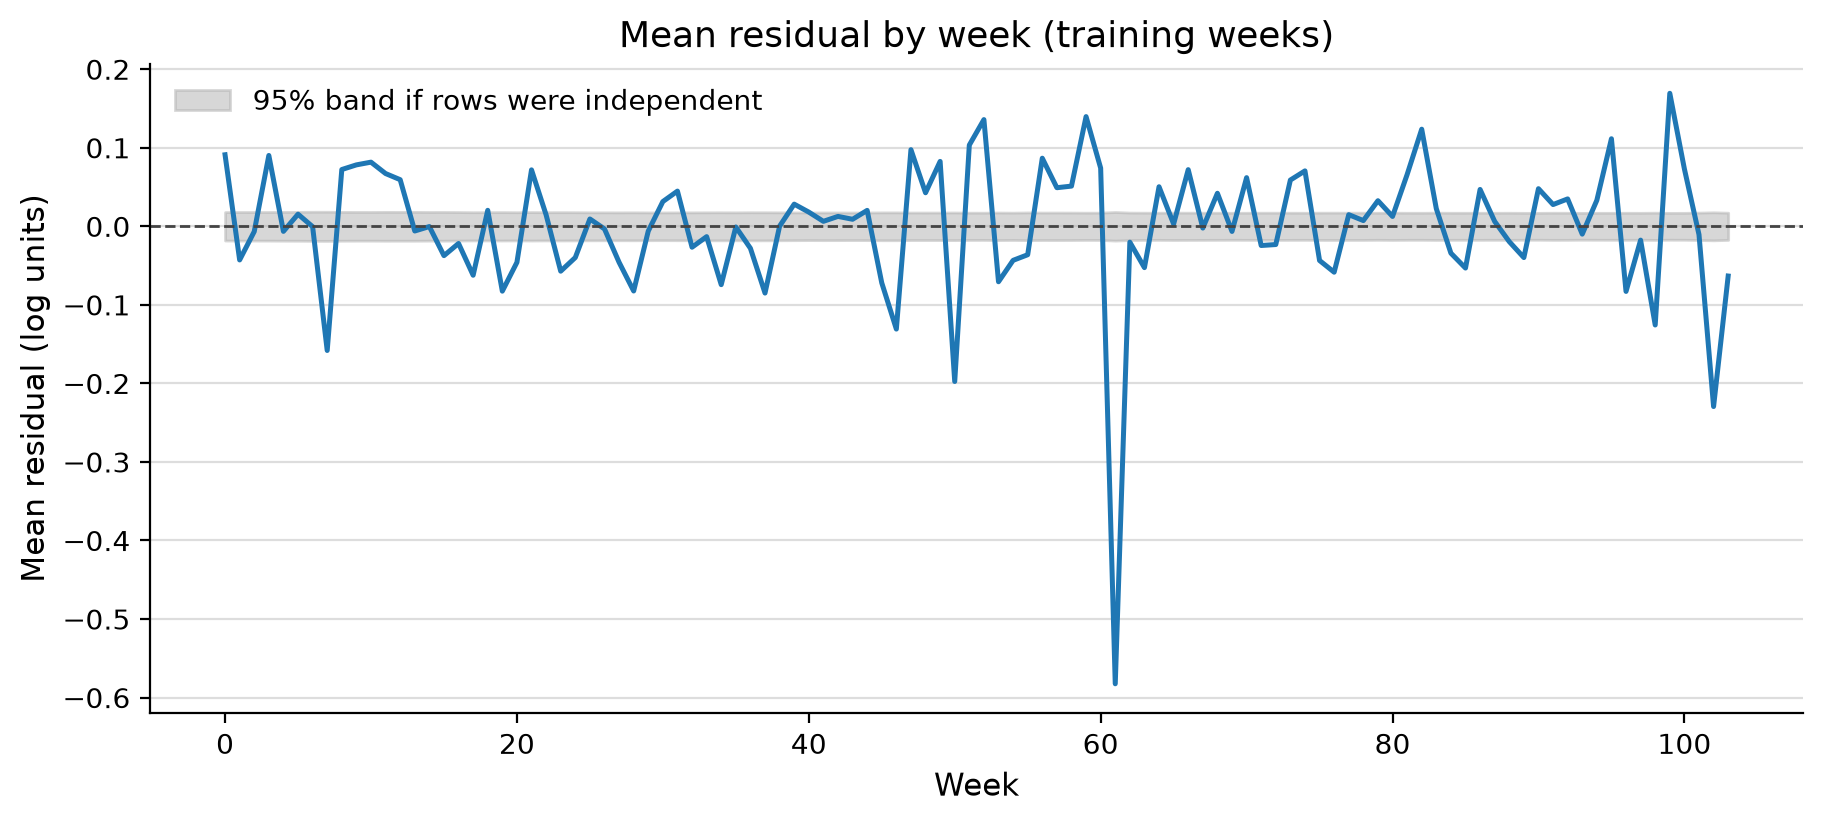

In [17]:
shocks = run_diag.load_table("week_shocks")
fig = viz.plot_week_shocks(shocks, LANG)
with pd.option_context("display.float_format", "{:,.6f}".format):
    display(run_diag.load_table("week_summary").iloc[0].to_frame("value"))
largest = shocks.loc[shocks["mean_resid"].abs().idxmax()]
week_end = panel.loc[panel["WEEK"] == largest["WEEK"], "WEEK_END_DATE"].iloc[0].date().isoformat()
outside = int((shocks["mean_resid"].abs() > 1.96 * shocks["expected_sd"]).sum())
display(
    pd.Series(
        {
            "weeks_outside_band": outside,
            "weeks": len(shocks),
            "largest_shock_week": int(largest["WEEK"]),
            "largest_shock_week_end": week_end,
            "largest_shock_mean_resid": largest["mean_resid"],
        },
        dtype=object,
    ).to_frame("value")
)

The second chart shows the mean residual of each training week with the 95% band expected if the rows were independent. The variance of the weekly means is 0.007861, against 0.000081 expected under independence, a ratio of about 97. The share of the sum of squares of the residuals due to weeks is 2.8%, against 0.03% expected, and that of the category × week combination is 6.4%, against 0.12% expected. There are, therefore, shocks common to all the rows of a week, especially by category. The lag-1 autocorrelation of the weekly means is −0.005, that is, these shocks do not persist from one week to the next. In 79 of the 104 weeks, the mean falls outside the band. The largest is that of week 61 (week ending 2010-03-17), with a mean residual of −0.582, against an expected standard deviation of 0.009.

The marginal residuals, which do not subtract the random effects, were also stored in the run. They mostly reflect the store, product and pair effects, and are not informative about the Wald intervals.

Taken together, the conditional residuals of F3 are not independent: there is positive serial correlation within the pair and shocks common to the week and the category. This dependence concerns the uncertainty, not the point estimates, which coincide with those of a pair and week fixed-effects estimator (section 9). The Wald intervals of F3 are conditional on the F3 specification and too narrow. After this notebook, standard errors clustered by pair and by week (Cameron et al., 2011) were computed on the fixed-effects estimator (run `fe_sensitivity`, decision register, amendment E4): they are 4.1 to 7.4 times the F3 Wald ones, with week clustering dominant, and the signs of the estimates hold.

Price and promotion are decided by the retailer itself, and are not assigned at random. If promotions are planned for weeks of already high demand (or if discounts are applied in response to inventory and competition), part of the estimated association reflects this selection, and the coefficients describe conditional associations, not causal effects (endogeneity; Villas-Boas & Winer, 1999). A pricing recommendation or an incremental ROI would require causal identification and margin data, which the project does not have. The log-log specification also imposes a constant elasticity: a 10% discount and a 30% discount act with the same elasticity, which is an approximation, and the overlap between promotion types and discount bands (section 4) limits the comparisons between promotions.

Residual dependence was measured (section 10): there is a serial correlation of 0.196 between consecutive weeks of the same pair and shocks common to the week. It was not modelled, and the Wald intervals of F3 are conditional on its specification and too narrow, as the clustered standard errors of section 9, 2.2 to 4.1 times larger, indicate. In addition, the formulation (the price decomposition of D12 and the others) was motivated by the initial exploration of the panel, which included the final 52 weeks, and is a development decision. No model was fitted on those weeks, and no predictive comparison was computed on them.

Only the observed weeks were modelled (D3), so the estimates are conditional on there being a sale in the pair that week, and do not include weeks without a record, which could be zero sales or a stock-out. Finally, the model estimates a single elasticity for all stores and products, whereas the interest of the project lies precisely in how the price effect varies among them. This last limitation motivates notebook 04.

## 12. Conclusions and next step

With the hierarchy kept (random intercepts for store, product and pair), a 10% deeper discount is associated with about 19.4% more units (elasticity of −1.685), and a 10% higher regular price with about 14.1% fewer. Feature (+64.4%) and display (+50.5%) are associated with more units beyond the discount, and the TPR flag has a coefficient of −0.041 (−4.0%), a value that depends on comparing weeks with no promotion at the same discount, a comparison that the data hardly contain. For the business reading, the joint discount-and-promotion scenarios of section 4 (for example, TPR with a 10% discount, +14.6%, and with 20%, +39.8%) have support in the data, and those that combine feature or display without a discount have lower support. The trend is −2.1% per year, and seasonality, from −4.2% to +6.6% around the average week, is small compared with the price associations. All these values are conditional associations in weeks with recorded transactions.

Price and promotion explain 34.4% of the weekly variance within the pair and 29.3% of the variance between products, and the small negative pseudo-R² values at the store and pair levels are a known artefact. The pooled OLS estimates a discount elasticity of −0.36, against −1.69 for the multilevel model. Excluding the 111 fallback rows barely changes the estimates, and the regression with pair and week fixed effects reproduces the F3 point estimates within 0.02, with clustered standard errors 2.2 to 4.1 times larger. The conditional residuals have a correlation of 0.196 between consecutive weeks and shocks common to the week. The dependence affects the uncertainty, not the point estimates, and the Wald intervals of F3 are conditional on the specification and too narrow; the standard errors clustered by pair and by week, recorded in amendment E4, are 4.1 to 7.4 times larger.

Notebook 04 presents the results of the pre-registered protocol P1, approved with amendments, on whether letting the discount elasticity vary across stores and products improves out-of-sample prediction.

## References

Bates, D., Mächler, M., Bolker, B., & Walker, S. (2015). Fitting linear mixed-effects models using lme4. *Journal of Statistical Software, 67*(1), 1–48. https://doi.org/10.18637/jss.v067.i01

Bijmolt, T. H. A., van Heerde, H. J., & Pieters, R. G. M. (2005). New empirical generalizations on the determinants of price elasticity. *Journal of Marketing Research, 42*(2), 141–156. https://doi.org/10.1509/jmkr.42.2.141.62296

Blattberg, R. C., & Neslin, S. A. (1989). Sales promotion: The long and the short of it. *Marketing Letters, 1*(1), 81–97. https://doi.org/10.1007/BF00436151

Cameron, A. C., & Miller, D. L. (2015). A practitioner's guide to cluster-robust inference. *Journal of Human Resources, 50*(2), 317–372. https://doi.org/10.3368/jhr.50.2.317

Cameron, A. C., Gelbach, J. B., & Miller, D. L. (2011). Robust inference with multiway clustering. *Journal of Business & Economic Statistics, 29*(2), 238–249. https://doi.org/10.1198/jbes.2010.07136

Gelman, A., & Hill, J. (2007). *Data analysis using regression and multilevel/hierarchical models*. Cambridge University Press. https://doi.org/10.1017/CBO9780511790942

Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.). OTexts. https://otexts.com/fpp3/

Mundlak, Y. (1978). On the pooling of time series and cross section data. *Econometrica, 46*(1), 69–85. https://doi.org/10.2307/1913646

Pinheiro, J. C., & Bates, D. M. (2000). *Mixed-effects models in S and S-PLUS*. Springer. https://doi.org/10.1007/b98882

Raudenbush, S. W., & Bryk, A. S. (2002). *Hierarchical linear models: Applications and data analysis methods* (2nd ed.). Sage. (partial verification: edition year not checked against a primary source)

Tellis, G. J. (1988). The price elasticity of selective demand: A meta-analysis of econometric models of sales. *Journal of Marketing Research, 25*(4), 331–341. https://doi.org/10.1177/002224378802500401

Villas-Boas, J. M., & Winer, R. S. (1999). Endogeneity in brand choice models. *Management Science, 45*(10), 1324–1338. https://doi.org/10.1287/mnsc.45.10.1324

Wooldridge, J. M. (2010). *Econometric analysis of cross section and panel data* (2nd ed.). MIT Press. (partial verification: edition year not checked against a primary source)